# Bayesian Image Classifier with Class-wise Means and Full Covariance Matrices

A Gaussian Bayes classifier (QDA) written from scratch with NumPy/SciPy, tested on the 8x8 handwritten digits dataset.

For class k:

$$\log p(k \mid x) = \log \pi_k \;-\; \tfrac{1}{2}\log\lvert\Sigma_k\rvert \;-\; \tfrac{1}{2}\,(x-\mu_k)^{\top}\Sigma_k^{-1}(x-\mu_k) \;-\; \tfrac{d}{2}\log 2\pi \;-\; \log p(x)$$

Decision rule (MAP): predict the class with the largest log posterior.



In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import cholesky, solve_triangular
from scipy.special import logsumexp
from scipy.stats import multivariate_normal
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold

RNG = 0

## 1. The classifier
`cov_type` can be `'full'` (one Σ_k per class), `'shared'` (pooled Σ, i.e. LDA) or `'diag'` (naive Bayes) so we can compare covariance structures later.

In [2]:
class GaussianBayes:
    def __init__(self, reg=1e-2, cov_type="full"):
        self.reg, self.cov_type = reg, cov_type

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        K, d = len(self.classes_), X.shape[1]
        self.d_ = d
        self.means_ = np.zeros((K, d))
        self.log_priors_ = np.zeros(K)
        covs = []
        for i, c in enumerate(self.classes_):
            Xc = X[y == c]
            self.means_[i] = Xc.mean(0)
            self.log_priors_[i] = np.log(len(Xc) / len(X))
            covs.append(np.cov(Xc, rowvar=False))
        covs = np.array(covs)
        if self.cov_type == "shared":
            w = np.exp(self.log_priors_)
            covs = np.repeat(np.tensordot(w, covs, axes=1)[None], K, axis=0)
        elif self.cov_type == "diag":
            covs = np.array([np.diag(np.diag(S)) for S in covs])
        # ridge regularization: needed because some pixels are constant -> singular covariance
        self.covs_ = covs + self.reg * np.eye(d)[None]
        self.chol_, self.logdet_ = [], np.zeros(K)
        for i in range(K):
            L = cholesky(self.covs_[i], lower=True)   # raises LinAlgError if not positive definite
            self.chol_.append(L)
            self.logdet_[i] = 2 * np.log(np.diag(L)).sum()
        return self

    def terms(self, X):
        """Per-class additive pieces of the log-joint, each of shape (n, K)."""
        n, K = len(X), len(self.classes_)
        maha = np.zeros((n, K))
        for i in range(K):
            z = solve_triangular(self.chol_[i], (X - self.means_[i]).T, lower=True)
            maha[:, i] = (z ** 2).sum(0)
        return {
            "prior":  np.tile(self.log_priors_, (n, 1)),
            "logdet": np.tile(-0.5 * self.logdet_, (n, 1)),
            "maha":   -0.5 * maha,
            "const":  -0.5 * self.d_ * np.log(2 * np.pi) * np.ones((n, K)),
        }

    def log_joint(self, X):
        return sum(self.terms(X).values())

    def predict_log_proba(self, X):
        lj = self.log_joint(X)
        return lj - logsumexp(lj, axis=1, keepdims=True)

    def predict_proba(self, X):
        return np.exp(self.predict_log_proba(X))

    def predict(self, X):
        return self.classes_[self.log_joint(X).argmax(1)]


def cv_accuracy(X, y, reg, cov_type, folds=5):
    accs = []
    for tr, va in StratifiedKFold(folds, shuffle=True, random_state=RNG).split(X, y):
        m = GaussianBayes(reg, cov_type).fit(X[tr], y[tr])
        accs.append((m.predict(X[va]) == y[va]).mean())
    return np.mean(accs)


def confusion(y, p, K=10):
    C = np.zeros((K, K), int)
    for t, q in zip(y, p):
        C[t, q] += 1
    return C

## 2. Data
Pixels are scaled to [0, 1]. 70/30 stratified train/test split.

In [3]:
digits = load_digits()
X = digits.data / 16.0
y = digits.target
idx = np.arange(len(y))
Xtr, Xte, ytr, yte, itr, ite = train_test_split(X, y, idx, test_size=0.3, stratify=y, random_state=RNG)
print(f"Train {Xtr.shape}, Test {Xte.shape}")
print(f"Constant pixels in train: {(Xtr.std(0) == 0).sum()} of 64")

Train (1257, 64), Test (540, 64)
Constant pixels in train: 4 of 64


## 3. Why regularize, and choosing λ by cross-validation
Without regularization the covariance is singular and the fit fails. We sweep the ridge λ for all three covariance structures.

reg=0 fails: LinAlgError -> covariance is singular

lambda        full   shared     diag
  0.0001   0.9634   0.9459   0.9117
  0.0003   0.9698   0.9467   0.9141
  0.0010   0.9714   0.9483   0.9228
  0.0032   0.9817   0.9507   0.9236
  0.0100   0.9873   0.9515   0.9236
  0.0316   0.9857   0.9491   0.9244
  0.1000   0.9841   0.9332   0.9069
  0.3162   0.9714   0.9173   0.8918
  1.0000   0.9419   0.9053   0.8799
Best lambda: {'full': 0.01, 'shared': 0.01, 'diag': 0.0316}


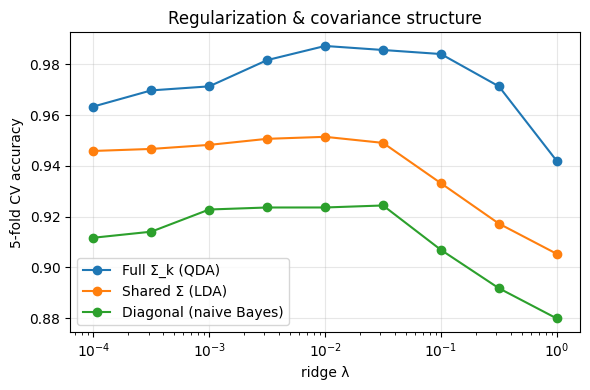

In [4]:
try:
    GaussianBayes(reg=0.0).fit(Xtr, ytr)
except Exception as e:
    print("reg=0 fails:", type(e).__name__, "-> covariance is singular")

grid = np.logspace(-4, 0, 9)
sweep = {ct: np.array([cv_accuracy(Xtr, ytr, r, ct) for r in grid]) for ct in ["full", "shared", "diag"]}
best = {ct: grid[sweep[ct].argmax()] for ct in sweep}

print("\nlambda     " + "  ".join(f"{ct:>7}" for ct in sweep))
for j, r in enumerate(grid):
    print(f"{r:8.4f}  " + "  ".join(f"{sweep[ct][j]:7.4f}" for ct in sweep))
print("Best lambda:", {k: round(float(v), 4) for k, v in best.items()})

fig, ax = plt.subplots(figsize=(6, 4))
for ct, lab in [("full", "Full Σ_k (QDA)"), ("shared", "Shared Σ (LDA)"), ("diag", "Diagonal (naive Bayes)")]:
    ax.semilogx(grid, sweep[ct], "o-", label=lab)
ax.set_xlabel("ridge λ"); ax.set_ylabel("5-fold CV accuracy"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("Regularization & covariance structure")
plt.tight_layout(); plt.show()

## 4. Test performance

   full covariance (λ=0.01): test accuracy 0.9907
 shared covariance (λ=0.01): test accuracy 0.9611
   diag covariance (λ=0.03162): test accuracy 0.9111

Full-covariance model: 535/540 correct, 5 errors

Per-class precision / recall / F1
digit 0: P=1.000 R=1.000 F1=1.000
digit 1: P=0.965 R=1.000 F1=0.982
digit 2: P=1.000 R=0.981 F1=0.990
digit 3: P=0.982 R=0.982 F1=0.982
digit 4: P=1.000 R=0.981 F1=0.991
digit 5: P=1.000 R=1.000 F1=1.000
digit 6: P=1.000 R=1.000 F1=1.000
digit 7: P=1.000 R=1.000 F1=1.000
digit 8: P=0.981 R=0.981 F1=0.981
digit 9: P=0.981 R=0.981 F1=0.981


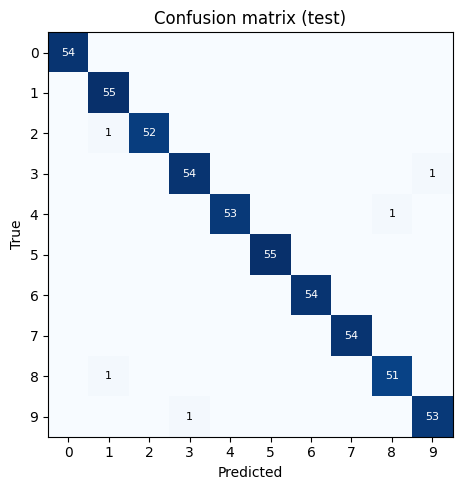

In [5]:
models = {ct: GaussianBayes(best[ct], ct).fit(Xtr, ytr) for ct in sweep}
for ct, m in models.items():
    print(f"{ct:>7} covariance (λ={best[ct]:.4g}): test accuracy {(m.predict(Xte) == yte).mean():.4f}")

model = models["full"]
P = model.predict_proba(Xte)
pred = model.classes_[P.argmax(1)]
correct = pred == yte
conf = P.max(1)
n_err = (~correct).sum()
print(f"\nFull-covariance model: {correct.sum()}/{len(yte)} correct, {n_err} errors")

C = confusion(yte, pred)
print("\nPer-class precision / recall / F1")
for k in range(10):
    tp = C[k, k]; prec = tp / max(C[:, k].sum(), 1); rec = tp / C[k].sum()
    print(f"digit {k}: P={prec:.3f} R={rec:.3f} F1={2*prec*rec/max(prec+rec,1e-12):.3f}")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.imshow(C, cmap="Blues")
for i in range(10):
    for j in range(10):
        if C[i, j]:
            ax.text(j, i, C[i, j], ha="center", va="center",
                    color="white" if C[i, j] > C.max()/2 else "black", fontsize=8)
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix (test)")
plt.tight_layout(); plt.show()

## 5. What the model learned: class means and pixel variances

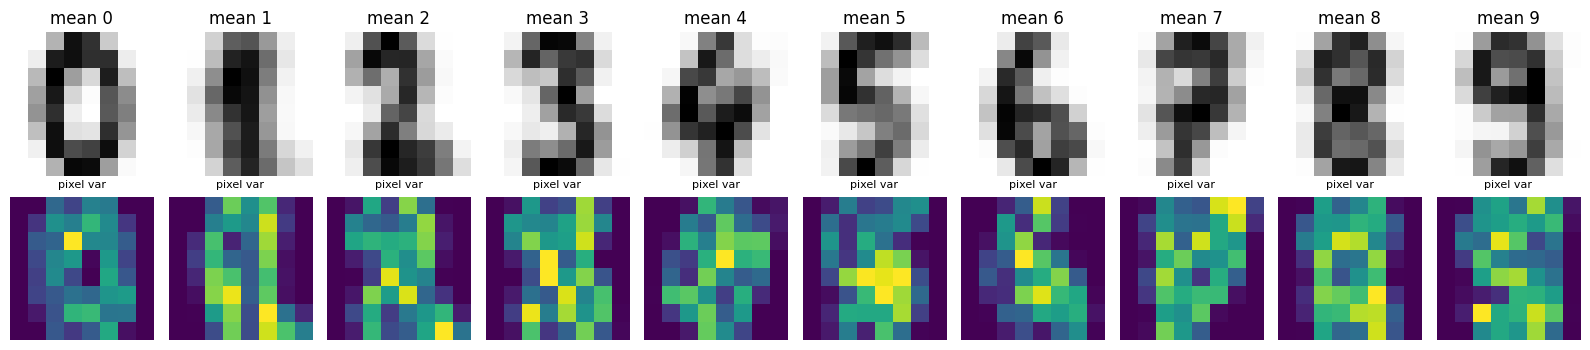

In [6]:
fig, ax = plt.subplots(2, 10, figsize=(16, 3.6))
for k in range(10):
    ax[0, k].imshow(model.means_[k].reshape(8, 8), cmap="gray_r"); ax[0, k].set_title(f"mean {k}")
    ax[1, k].imshow(np.diag(model.covs_[k]).reshape(8, 8), cmap="viridis"); ax[1, k].set_title("pixel var", fontsize=8)
    ax[0, k].axis("off"); ax[1, k].axis("off")
plt.tight_layout(); plt.show()

## 6. Confidence and calibration

Mean max-posterior | correct: 0.9996   wrong: 0.7335
Errors with confidence > 0.9: 2 / 5
Expected calibration error: 0.0064   Test NLL: 0.0612


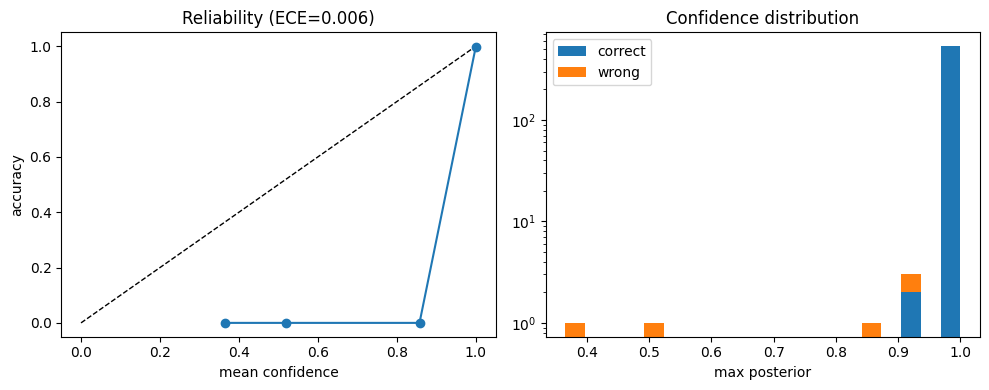

In [7]:
print(f"Mean max-posterior | correct: {conf[correct].mean():.4f}   wrong: {conf[~correct].mean():.4f}")
print(f"Errors with confidence > 0.9: {(conf[~correct] > 0.9).sum()} / {n_err}")

bins = np.linspace(0, 1, 11)
ece, rel = 0.0, []
for lo, hi in zip(bins[:-1], bins[1:]):
    m = (conf > lo) & (conf <= hi)
    if m.sum():
        a, c_ = correct[m].mean(), conf[m].mean()
        ece += m.mean() * abs(a - c_)
        rel.append((c_, a, m.sum()))
nll = -np.log(np.clip(P[np.arange(len(yte)), yte], 1e-300, 1)).mean()
print(f"Expected calibration error: {ece:.4f}   Test NLL: {nll:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
r = np.array(rel)
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].plot(r[:, 0], r[:, 1], "o-")
ax[0].set_xlabel("mean confidence"); ax[0].set_ylabel("accuracy"); ax[0].set_title(f"Reliability (ECE={ece:.3f})")
ax[1].hist([conf[correct], conf[~correct]], bins=20, label=["correct", "wrong"], stacked=True, log=True)
ax[1].set_xlabel("max posterior"); ax[1].legend(); ax[1].set_title("Confidence distribution")
plt.tight_layout(); plt.show()

## 7. Why does it misclassify? Decomposing each decision
The log-joint splits into prior + log-determinant + Mahalanobis terms. For each error we compare (predicted class − true class) for each term.

Mean contribution to the (predicted − true) log-joint margin over errors:
   prior:    +0.00
  logdet:    +0.34
    maha:    +5.84
  total :    +6.19

Errors where Mahalanobis distance alone picks the true class: 2 / 5
Errors where the log|Σ| term favored the predicted class:     3 / 5

Per-class log|Σ_k|: {0: -251.0, 1: -244.3, 2: -242.9, 3: -240.2, 4: -242.4, 5: -238.5, 6: -250.9, 7: -240.6, 8: -235.2, 9: -236.9}

Most confident errors (test idx | true -> pred | conf | p(true)):
   1660 | 4 -> 8 | 1.0000 | 9.44e-12
    794 | 8 -> 1 | 0.9268 | 7.32e-02
   1038 | 9 -> 3 | 0.8572 | 1.43e-01
     77 | 2 -> 1 | 0.5180 | 4.82e-01
   1118 | 3 -> 9 | 0.3654 | 1.17e-01


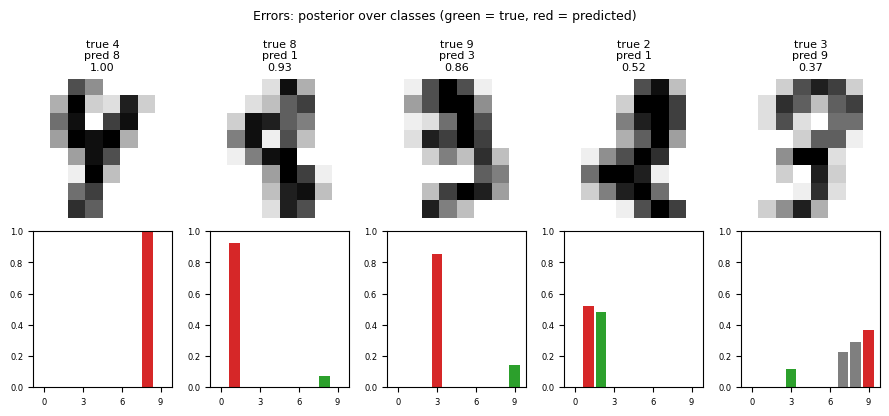

In [8]:
T = model.terms(Xte)
ti = np.searchsorted(model.classes_, yte)
pi = np.searchsorted(model.classes_, pred)
e = np.where(~correct)[0]

d_terms = {k: T[k][e, pi[e]] - T[k][e, ti[e]] for k in ["prior", "logdet", "maha"]}
print("Mean contribution to the (predicted − true) log-joint margin over errors:")
for k, v in d_terms.items():
    print(f"  {k:>6}: {v.mean():+8.2f}")
print(f"  total : {sum(d_terms.values()).mean():+8.2f}")

maha_only = (-2 * T["maha"]).argmin(1)
print(f"\nErrors where Mahalanobis distance alone picks the true class: {(maha_only[e] == ti[e]).sum()} / {n_err}")
print(f"Errors where the log|Σ| term favored the predicted class:     {(d_terms['logdet'] > 0).sum()} / {n_err}")
print("\nPer-class log|Σ_k|:", {int(c): round(float(v), 1) for c, v in zip(model.classes_, model.logdet_)})

show = e[np.argsort(-conf[e])][:min(10, n_err)]
print("\nMost confident errors (test idx | true -> pred | conf | p(true)):")
for t in show:
    print(f"  {ite[t]:5d} | {yte[t]} -> {pred[t]} | {conf[t]:.4f} | {P[t, ti[t]]:.2e}")

fig, ax = plt.subplots(2, len(show), figsize=(1.8 * len(show), 4.2), squeeze=False)
for j, t in enumerate(show):
    ax[0, j].imshow(Xte[t].reshape(8, 8), cmap="gray_r"); ax[0, j].axis("off")
    ax[0, j].set_title(f"true {yte[t]}\npred {pred[t]}\n{conf[t]:.2f}", fontsize=8)
    cols = ["tab:gray"] * 10; cols[ti[t]] = "tab:green"; cols[pi[t]] = "tab:red"
    ax[1, j].bar(range(10), P[t], color=cols); ax[1, j].set_ylim(0, 1)
    ax[1, j].set_xticks(range(0, 10, 3)); ax[1, j].tick_params(labelsize=6)
fig.suptitle("Errors: posterior over classes (green = true, red = predicted)", fontsize=9)
plt.tight_layout(); plt.show()

## 8. Sanity check against SciPy

In [9]:
ref = np.column_stack([
    multivariate_normal(model.means_[i], model.covs_[i]).logpdf(Xte[:50]) + model.log_priors_[i]
    for i in range(10)])
print(f"Max |log-joint difference| vs scipy: {np.abs(ref - model.log_joint(Xte[:50])).max():.2e}")
print("Posteriors sum to 1:", np.allclose(P.sum(1), 1))

Max |log-joint difference| vs scipy: 4.55e-13
Posteriors sum to 1: True
